# Imports

In [1]:
import torch 
import torch.nn as nn
import math
import typing
from typing import List, Union
import pandas as pd
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

In [2]:
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# Dataset

In [3]:
df = pd.read_csv(r'df_trainset_v3.csv')
print(df.shape)
df.head(2)

(4606, 12)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,encode_position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.25,"[0.6820112650872491, 0.4728664244776024]",0.027811,"[-0.01566934209907833, -0.06868062391330976]",0.026323,"[-0.4258184861370507, -0.9048086078635362]",CTYTRCRZKVYTLGNIIWLC,[[0.20793835 0.32408492 0.3349807 0.68008423 ...,62,0.132196,63.0,1
1,0.55,"[0.663985472742647, 0.4591009778508717]",0.051235,"[-0.09298784207982802, -0.030763312846688873]",-4.067070,"[-0.8391207421663309, -0.5439451995065551]",RCRZCTYTKVYTLGNIIWLC,[[0.32408492 0.20793835 0.3349807 0.68008423 ...,260,0.554371,62.0,1


In [4]:
token_to_ps = {pid:ps for pid, ps in zip(df['position_state_id'], df['position_state'])}
ps_to_token = {ps:pid for pid, ps in zip(df['position_state_id'], df['position_state'])}

In [4]:
df['position_state_id'].nunique()

469

In [5]:
df['position_state_id'].describe()

count    4606.000000
mean      215.103995
std       134.838436
min         0.000000
25%        89.000000
50%       209.000000
75%       331.000000
max       468.000000
Name: position_state_id, dtype: float64

<Axes: >

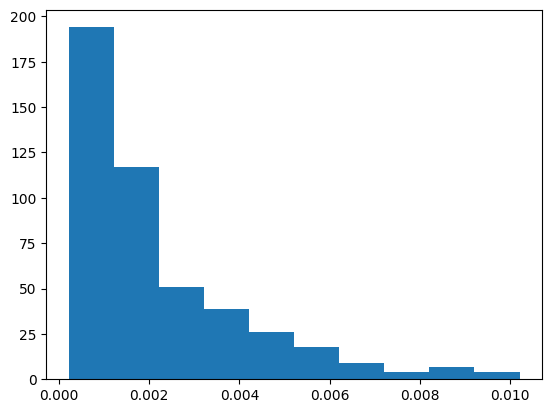

In [6]:
df['position_state_id'].value_counts(normalize=True).hist(grid=False, )

<Axes: >

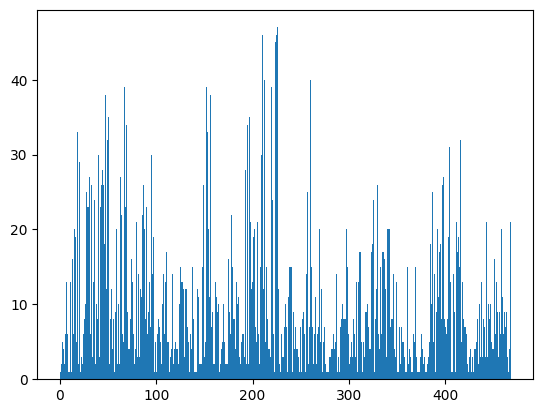

In [7]:
df['position_state_id'].hist(grid=False, bins=range(df['position_state_id'].nunique()))

## tokenized dataset

In [8]:
df['position_state_id'].head()

0     62
1    260
2    256
3    255
4    249
Name: position_state_id, dtype: int64

# Classes

In [36]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn import TransformerDecoder, TransformerDecoderLayer
import random

# Exemplo de dataset toy com 'position_state_id'
class PositionStateDataset(Dataset):
    def __init__(self, sequences, seq_length):
        self.sequences = sequences
        self.seq_length = seq_length

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        seq = self.sequences[idx]
        x = torch.tensor(seq[:-1], dtype=torch.long)
        y = torch.tensor(seq[1:], dtype=torch.long)
        return x, y
    

class SequentialTokenDataset(Dataset):
    def __init__(self, data, seq_length):
        self.data = torch.tensor(data, dtype=torch.long)
        self.seq_length = seq_length

    def __len__(self):
        return len(self.data) - self.seq_length

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.seq_length]
        y = self.data[idx + 1 : idx + self.seq_length + 1]
        return x, y


# Modelo Decoder Transformer
class DecoderTransformerModel(nn.Module):
    def __init__(self, vocab_size, embed_size, num_layers, num_heads, hidden_dim, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.pos_embedding = nn.Embedding(500, embed_size)  # máx comprimento fixo

        decoder_layer = TransformerDecoderLayer(d_model=embed_size, nhead=num_heads, dim_feedforward=hidden_dim, dropout=dropout)
        self.transformer_decoder = TransformerDecoder(decoder_layer, num_layers=num_layers)

        self.fc_out = nn.Linear(embed_size, vocab_size)

    def forward(self, tgt, memory=None):
        seq_len = tgt.size(1)
        pos = torch.arange(0, seq_len).unsqueeze(0).to(tgt.device)
        tgt_embed = self.embedding(tgt) + self.pos_embedding(pos)

        # Máscara para garantir autoregressão
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(seq_len).to(tgt.device)

        output = self.transformer_decoder(tgt_embed.transpose(0, 1), memory=None, tgt_mask=tgt_mask)
        output = self.fc_out(output.transpose(0, 1))
        return output

class EncoderTransformerModel(nn.Module):
    def __init__(self, vocab_size, embed_size, num_layers, num_heads, hidden_dim, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.pos_embedding = nn.Embedding(500, embed_size)  # suporte até 500 posições

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_size, 
            nhead=num_heads, 
            dim_feedforward=hidden_dim, 
            dropout=dropout
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.fc_out = nn.Linear(embed_size, vocab_size)

    def forward(self, x):
        seq_len = x.size(1)
        pos = torch.arange(0, seq_len, device=x.device).unsqueeze(0)
        x_embed = self.embedding(x) + self.pos_embedding(pos)

        # Máscara causal para autoregressão
        mask = nn.Transformer.generate_square_subsequent_mask(seq_len).to(x.device)

        out = self.transformer(x_embed.transpose(0, 1), mask=mask)
        out = self.fc_out(out.transpose(0, 1))
        return out

def generate_sequence(model, start_sequence, max_new_tokens, vocab_size):
    """
    Gera uma sequência a partir de uma sequência inicial usando o modelo treinado.

    Args:
        model: modelo treinado (DecoderTransformerModel)
        start_sequence: lista de tokens inteiros (input inicial)
        max_new_tokens: número de novos tokens a gerar
        vocab_size: tamanho do vocabulário

    Returns:
        Lista de tokens com a sequência completa (entrada + tokens gerados)
    """
    model.eval()
    generated = start_sequence[:]
    input_tensor = torch.tensor(generated, dtype=torch.long).unsqueeze(0).to(device)  # [1, seq_len]

    for _ in range(max_new_tokens):
        if input_tensor.size(1) > 500:  # Limite posicional do modelo
            input_tensor = input_tensor[:, -500:]

        with torch.no_grad():
            logits = model(input_tensor)  # [1, seq_len, vocab_size]
            next_token_logits = logits[:, -1, :]  # Última posição
            probs = torch.softmax(next_token_logits, dim=-1)
            next_token = torch.argmax(probs, dim=-1).item()  # greedy
            # Para sampling aleatório: next_token = torch.multinomial(probs, num_samples=1).item()

        generated.append(next_token)
        input_tensor = torch.tensor(generated, dtype=torch.long).unsqueeze(0).to(device)

    return generated


In [ ]:
# Hiperparâmetros
embed_size = 512
num_layers = 2
num_heads = 4
hidden_dim = 1024
vocab_size = df['position_state_id'].nunique()
seq_length = 7
dropout = 0.3
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_epochs = 30
# Simulando dados
sequences = df['position_state_id'].values

device, vocab_size

(device(type='cuda'), 469)

In [68]:
np.max(sequences)

468

In [69]:
dataset = SequentialTokenDataset(sequences, seq_length)

In [70]:
# model = DecoderTransformerModel(vocab_size, embed_size, num_layers, num_heads, hidden_dim).to(device)
model = EncoderTransformerModel(vocab_size, embed_size, num_layers, num_heads, hidden_dim, dropout).to(device)

In [71]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

In [72]:
# Dividindo dataset em treino e validação (exemplo simples)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

train_size, val_size

(3679, 920)

In [73]:
train_losses = []
val_losses = []

for epoch in range(int(num_epochs)):
    model.train()
    train_loss = 0.0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()

        output = model(x)
        loss = criterion(output.view(-1, vocab_size), y.view(-1))
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # Validação
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_val, y_val in val_loader:
            x_val, y_val = x_val.to(device), y_val.to(device)
            val_output = model(x_val)
            v_loss = criterion(val_output.view(-1, vocab_size), y_val.view(-1))
            val_loss += v_loss.item()

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)

    # Salva os valores para plot
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")


Epoch 1/30 | Train Loss: 5.2882 | Val Loss: 4.0090
Epoch 2/30 | Train Loss: 3.3275 | Val Loss: 2.4439
Epoch 3/30 | Train Loss: 2.2987 | Val Loss: 1.8397
Epoch 4/30 | Train Loss: 1.8064 | Val Loss: 1.5450
Epoch 5/30 | Train Loss: 1.5291 | Val Loss: 1.3581
Epoch 6/30 | Train Loss: 1.3515 | Val Loss: 1.2322
Epoch 7/30 | Train Loss: 1.2296 | Val Loss: 1.1522
Epoch 8/30 | Train Loss: 1.1381 | Val Loss: 1.0898
Epoch 9/30 | Train Loss: 1.0727 | Val Loss: 1.0379
Epoch 10/30 | Train Loss: 1.0138 | Val Loss: 1.0098
Epoch 11/30 | Train Loss: 0.9734 | Val Loss: 0.9687
Epoch 12/30 | Train Loss: 0.9407 | Val Loss: 0.9487
Epoch 13/30 | Train Loss: 0.9121 | Val Loss: 0.9342
Epoch 14/30 | Train Loss: 0.8867 | Val Loss: 0.9225
Epoch 15/30 | Train Loss: 0.8651 | Val Loss: 0.9066
Epoch 16/30 | Train Loss: 0.8478 | Val Loss: 0.8961
Epoch 17/30 | Train Loss: 0.8316 | Val Loss: 0.8843
Epoch 18/30 | Train Loss: 0.8154 | Val Loss: 0.8787
Epoch 19/30 | Train Loss: 0.8005 | Val Loss: 0.8780
Epoch 20/30 | Train L

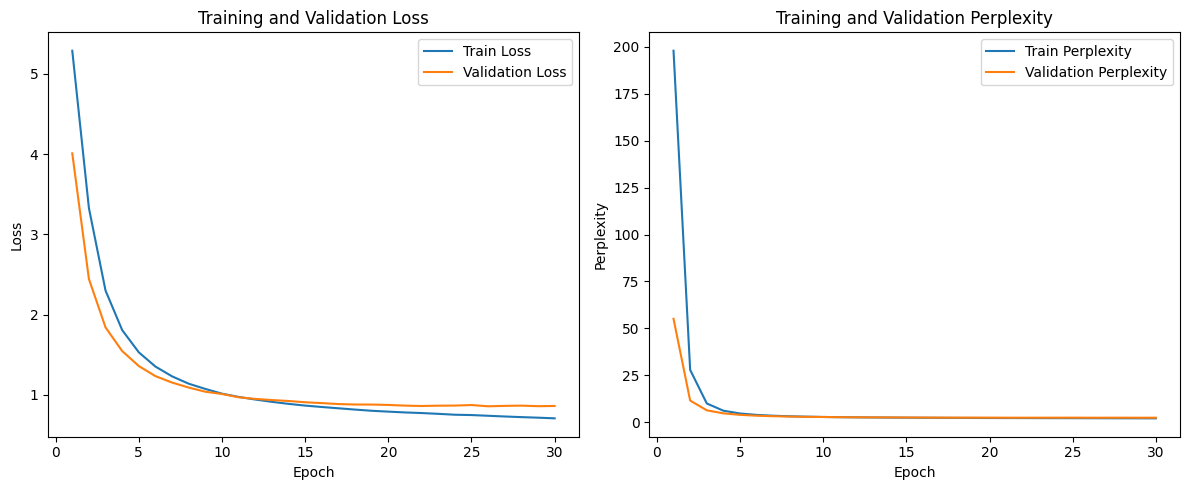

In [74]:
# Calcula perplexidade a partir das losses
train_perplexities = [np.exp(l) for l in train_losses]
val_perplexities = [np.exp(l) for l in val_losses]

# Plot da loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, int(num_epochs) + 1), train_losses, label='Train Loss')
plt.plot(range(1, int(num_epochs) + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
# plt.grid(True)

# Plot da perplexidade
plt.subplot(1, 2, 2)
plt.plot(range(1, int(num_epochs) + 1), train_perplexities, label='Train Perplexity')
plt.plot(range(1, int(num_epochs) + 1), val_perplexities, label='Validation Perplexity')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.title('Training and Validation Perplexity')
plt.legend()
# plt.grid(True)

plt.tight_layout()
plt.show()


In [58]:
# Suponha que você tenha treinado o modelo com vocabulário de IDs numéricos
start = [62,]  # exemplo de sequência inicial

generated_tokens = generate_sequence(model, start_sequence=start, max_new_tokens=5, vocab_size=vocab_size)
print("Tokens gerados:", generated_tokens)

Tokens gerados: [62, 236, 451, 236, 418, 410]


In [59]:
for tk in generated_tokens:
    print(f'{token_to_ps[tk]}')

CTYTRCRZKVYTLGNIIWLC
PZXOSTLYRCRZRUIZBJUQ
YORDEOWABFXYMHQXRCRZ
PZXOSTLYRCRZRUIZBJUQ
STLYKLTPCTYTBJUQRCRZ
STLYBJUQRUIZPZXORCRZ


## InputEmbeddings